<font size = 3 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font> 

# Red neuronal sencilla con PyTorch

Red neuronal para aprender los distintos pasos del aprendizaje.
La red consiste en una capa de entrada de dos neuronas, una capa oculta de cuatro neuronas con función de activación ReLU
y una capa de salida con función sigmoidea.

Esta versión resuelve exactamente el mismo problema que el notebook `bp_hardwired_ReLU`, en el que la propagación hacia adelante, la retropropagación y el descenso de gradiente estaban programados a mano con NumPy. Aquí delegamos ese trabajo en **PyTorch**:

| Notebook original (NumPy) | Esta versión (PyTorch) |
|---|---|
| Pesos `w[l]` y sesgos `b[l]` en listas de arrays | Capas `nn.Linear` dentro de un `nn.Module` |
| `forward_prop` muestra a muestra | Método `forward`, que procesa un lote completo de una vez |
| `backprop` con las fórmulas de los deltas escritas a mano | `loss.backward()`: **diferenciación automática** (*autograd*) |
| Actualización `w ← w − η/B · Σ∇w` escrita a mano | Optimizador `torch.optim.SGD` |
| Siempre en CPU | En la **GPU** si el equipo tiene una, y si no en la CPU |

## Importación de librerías

Además de `numpy` y `matplotlib`, cargamos `torch` (tensores y diferenciación automática) y `torch.nn` (capas y funciones de pérdida). `time` sirve para medir la duración del entrenamiento.

In [15]:
%config InlineBackend.figure_format = 'retina'
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.6.0+cu124


## Comprobación de la GPU

PyTorch puede ejecutar los cálculos en distintos dispositivos (*devices*). Comprobamos cuál está disponible, por orden de preferencia:

1. **`cuda`**: una GPU de NVIDIA con los controladores CUDA instalados.
2. **`mps`**: la GPU de los Mac con chip Apple (M1, M2…).
3. **`cpu`**: si no hay ninguna de las anteriores.

A partir de aquí, todos los tensores y el modelo se envían a `device` con `.to(device)`. El resto del código es idéntico se ejecute donde se ejecute.

In [16]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU disponible:", torch.cuda.get_device_name(0))
    print(f"Memoria de la GPU: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
    print("GPU disponible: Apple Silicon (MPS)")
else:
    device = torch.device("cpu")
    print("No hay GPU disponible: se usará la CPU")
print("Dispositivo de cálculo:", device)

GPU disponible: NVIDIA GeForce MX450
Memoria de la GPU: 2.0 GB
Dispositivo de cálculo: cuda


## Funciones auxiliares

Definimos dos funciones que usaremos a lo largo del notebook:

- **`crea_datos(numpuntos)`**: genera puntos aleatorios $(x, y)$ en $[0,1]^2$ y les asigna una etiqueta binaria (0 o 1) según una regla geométrica. Se pueden activar distintas fronteras de decisión (recta, circunferencia, o tres regiones) comentando/descomentando las líneas correspondientes. Devuelve un array de forma `(numpuntos, 3)`: columnas $x$, $y$ y etiqueta. Usa NumPy con la misma semilla que el notebook original, así que **los datos son exactamente los mismos**.
- **`plot_data(data, plabels)`**: dibuja los puntos coloreados por clase (azul = clase 0, verde = clase 1). Si se pasan predicciones, los errores de clasificación se pintan en rojo.

In [17]:
def crea_datos(numpuntos):
    """Genera numpuntos muestras (x, y) aleatorias y su etiqueta. Devuelve un array (numpuntos, 3)."""
    x = np.random.rand(numpuntos)
    y = np.random.rand(numpuntos)
    #etiquetas = (x + y) < 1                              # Línea recta
    #etiquetas = (x**2 + y**2) < 0.5                      # Circunferencia
    etiquetas = ((x**2 + y**2) < 0.7**2) | (x > 0.9)      # Tres regiones
    return np.column_stack([x, y, etiquetas.astype(np.float64)])

def plot_data(data, plabels=None):
    """Dibuja los puntos del conjunto de datos coloreados por clase.
    Si se pasan plabels (predicciones), colorea según ellas: azul=0, verde=1, rojo=error."""
    fig = plt.figure(figsize=(5,5))
    ax = fig.add_subplot(111)
    cols = ["blue", "green", "red"]
    clases = data[:,2] if plabels is None else plabels
    for v in range(3):
        dplot = data[clases == v]
        ax.scatter(dplot[:,0], dplot[:,1], color=cols[v], s=10, zorder=50)
    ax.set_aspect('equal', 'datalim')
    plt.show()

## Creación del conjunto de datos

Generamos 10 000 puntos en total: el 80% para entrenamiento y el 20% para test. Fijamos las semillas de NumPy (datos) y de PyTorch (pesos iniciales y barajado) para que los resultados sean reproducibles. Después convertimos los datos en **tensores** y los enviamos al dispositivo de cálculo:

- `X_train`, `X_test`: entradas, de forma `(N, 2)`. **Cada fila es una muestra**.
- `y_train`, `y_test`: etiquetas, de forma `(N, 1)`, con el mismo formato que la salida de la red.

El conjunto de datos es pequeño (80 KB), así que cabe entero en la memoria de la GPU y no hace falta un `DataLoader`.

In [18]:
NUM_PUNTOS_ALL = 10000
NUM_PUNTOS_TRAIN = round(0.8*NUM_PUNTOS_ALL)
NUM_PUNTOS_TEST = NUM_PUNTOS_ALL - NUM_PUNTOS_TRAIN
# Fijamos las semillas para reproducibilidad
np.random.seed(2026)
torch.manual_seed(2026)

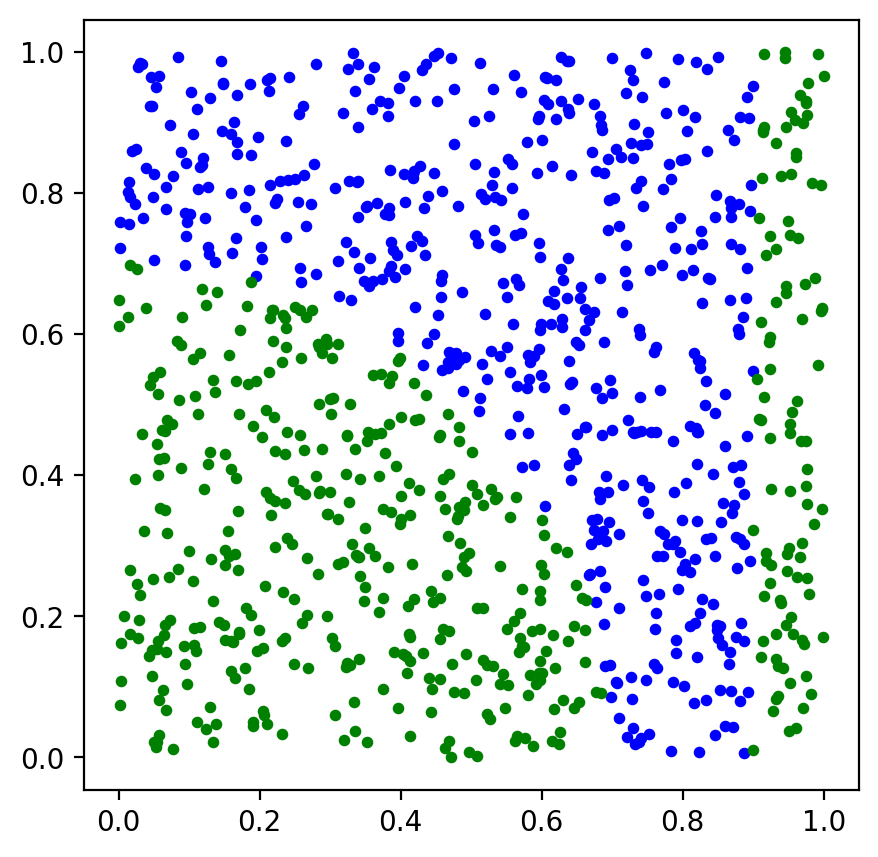

X_train: (8000, 2) | y_train: (8000, 1) | dispositivo: cuda:0


In [19]:
train_np = crea_datos(NUM_PUNTOS_TRAIN)
test_np = crea_datos(NUM_PUNTOS_TEST)
numpuntosplot = round(NUM_PUNTOS_ALL/10)
plot_data(train_np[0:numpuntosplot])

# Conversión a tensores float32 en el dispositivo de cálculo
X_train = torch.tensor(train_np[:, :2], dtype=torch.float32, device=device)
y_train = torch.tensor(train_np[:, 2:3], dtype=torch.float32, device=device)
X_test = torch.tensor(test_np[:, :2], dtype=torch.float32, device=device)
y_test = torch.tensor(test_np[:, 2:3], dtype=torch.float32, device=device)
print("X_train:", tuple(X_train.shape), "| y_train:", tuple(y_train.shape), "| dispositivo:", X_train.device)

La red consiste en una capa de entrada de dos neuronas, una capa oculta de cuatro neuronas con función de activación ReLU y una capa de salida con función sigmoidea.

## Definición del modelo

En PyTorch una red se define como una clase que hereda de `nn.Module`:

- En **`__init__`** se crean las capas. `nn.Linear(n_in, n_out)` contiene la matriz de pesos `weight`, de forma `(n_out, n_in)`, la misma que `w[l]` en el notebook original, y el vector de sesgos `bias`, que corresponde a `b[l]`. PyTorch registra automáticamente estos tensores como **parámetros entrenables**.
- En **`forward`** se describe el paso hacia adelante. Como la entrada es un lote con una muestra por fila, `nn.Linear` calcula $Z = A\,W^\top + b$, que es la misma operación que $z = W a + b$ aplicada a todas las muestras a la vez.

### Inicialización de pesos

Los pesos se inicializan igual que en el notebook original:

- **Capa oculta (ReLU)**: inicialización **He** — $w \sim \mathcal{N}\!\left(0,\, \sqrt{2/n_{\text{in}}}\right)$. Compensa que ReLU anula la mitad de las activaciones.
- **Capa de salida (sigmoid)**: inicialización **Xavier/Glorot** — $w \sim \mathcal{N}\!\left(0,\, \sqrt{1/n_{\text{in}}}\right)$.
- Los **sesgos** se inicializan a cero en ambas capas.

Si no lo hiciéramos, `nn.Linear` usaría su propia inicialización por defecto, una distribución uniforme.

Los números aleatorios se generan con **NumPy**, con la misma semilla y en el mismo orden que en el notebook original, para que la red **parta exactamente de los mismos pesos** y los resultados sean comparables. Esto importa más de lo que parece: con solo cuatro neuronas ocultas, el resultado depende mucho de la inicialización. Si alguna neurona ReLU empieza en una zona donde está siempre apagada (salida 0 para todos los puntos), no recibe gradiente y deja de aprender, y la red se queda con menos capacidad de la necesaria para la frontera de tres regiones. Puedes comprobarlo usando la alternativa con `nn.init.normal_` que aparece comentada y cambiando la semilla de `torch.manual_seed`: con algunas semillas la tasa de acierto en test supera el 95%, y con otras se queda por debajo del 80%.

In [20]:
n0, n1, n2 = 2, 4, 1   # neuronas por capa

class RedSencilla(nn.Module):
    def __init__(self):
        super().__init__()
        self.oculta = nn.Linear(n0, n1)    # w[1]: (4,2), b[1]: (4)
        self.salida = nn.Linear(n1, n2)    # w[2]: (1,4), b[2]: (1)
        # Inicialización He (capa ReLU) y Xavier (capa sigmoide), sesgos a cero.
        # Los valores se generan con NumPy para partir de los MISMOS pesos que el notebook original.
        # Alternativa "puramente PyTorch":
        #   nn.init.normal_(self.oculta.weight, mean=0.0, std=np.sqrt(2 / n0))
        #   nn.init.normal_(self.salida.weight, mean=0.0, std=np.sqrt(1 / n1))
        with torch.no_grad():
            self.oculta.weight.copy_(torch.from_numpy(np.random.randn(n1, n0) * np.sqrt(2 / n0)))
            self.salida.weight.copy_(torch.from_numpy(np.random.randn(n2, n1) * np.sqrt(1 / n1)))
        nn.init.zeros_(self.oculta.bias)
        nn.init.zeros_(self.salida.bias)

    def forward(self, x):
        a1 = torch.relu(self.oculta(x))          # z[1] = w[1]·a[0] + b[1];  a[1] = ReLU(z[1])
        return torch.sigmoid(self.salida(a1))    # z[2] = w[2]·a[1] + b[2];  a[2] = σ(z[2])

model = RedSencilla().to(device)
print(model)
print("Parámetros entrenables:", sum(p.numel() for p in model.parameters()))

RedSencilla(
  (oculta): Linear(in_features=2, out_features=4, bias=True)
  (salida): Linear(in_features=4, out_features=1, bias=True)
)
Parámetros entrenables: 17


## Hiperparámetros, función de coste y optimizador

Los hiperparámetros son los mismos que en el notebook original:

- **`learning_rate`**: tasa de aprendizaje $\eta$ para el descenso de gradiente.
- **`funcion_coste`**: función de coste a utilizar (`"mse"` o `"cross_entropy"`). La entropía cruzada es más adecuada para clasificación binaria con salida sigmoide.
- **`batch_length`**: tamaño de cada mini-batch en SGD.
- **`numepocas`**: número de pasadas completas por el conjunto de entrenamiento.

Las funciones de coste de PyTorch devuelven por defecto la **media** sobre las muestras del lote. Eso equivale exactamente al factor $\frac{\eta}{|\text{batch}|}\sum$ de la actualización original:

- `"cross_entropy"` → `nn.BCELoss()`: $C = -[y \log a + (1-y)\log(1-a)]$. Internamente limita el logaritmo para evitar $\log 0$, el mismo papel que tenía el `np.clip` del original.
- `"mse"` → `0.5 * nn.MSELoss()`: el factor $\frac{1}{2}$ reproduce el coste original $C = \frac{1}{2}(a-y)^2$.

El optimizador **`torch.optim.SGD`** aplica la regla $w \leftarrow w - \eta\,\nabla_w C$ a todos los parámetros del modelo. Todo el código de actualización a mano se sustituye por `optimizer.step()`.

In [21]:
learning_rate = 1                 # Si es pequeña (0.1) no funciona bien para las fronteras más complejas
funcion_coste = "cross_entropy"   # "mse" o "cross_entropy"
batch_length = 100
numepocas = 100

if funcion_coste == "cross_entropy":
    criterion = nn.BCELoss()
else:
    mse = nn.MSELoss()
    criterion = lambda salida, y: 0.5 * mse(salida, y)

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

## Evaluación de la clasificación

La función `evaluar_clasificacion` propaga **todas las muestras a la vez** por la red, aplica un umbral de 0.5 a la salida sigmoide para obtener la clase predicha (0 o 1) y cuenta los aciertos. Devuelve también las predicciones para poder visualizar los errores.

- `model.eval()` y `torch.no_grad()` indican que solo vamos a predecir. PyTorch no guarda la información necesaria para calcular gradientes, lo que ahorra memoria y tiempo.
- `.item()` y `.cpu().numpy()` traen los resultados de la GPU a la memoria principal.

In [22]:
def evaluar_clasificacion(X, y):
    """Predice todas las muestras con la red actual (umbral 0.5)
    y devuelve el número de aciertos y el array de predicciones."""
    model.eval()
    with torch.no_grad():
        pred = (model(X) > 0.5).float()
        aciertos = (pred == y).sum().item()
    return aciertos, pred.cpu().numpy().ravel()

## Evaluación inicial (antes de entrenar)

Evaluamos la tasa de acierto de la red con los pesos aleatorios iniciales. Esto nos da una línea base: para un clasificador binario con clases equilibradas, esperamos alrededor de un 50% de acierto por azar. Cualquier mejora tras el entrenamiento se mide respecto a este valor.

In [23]:
aciertos, predicciones = evaluar_clasificacion(X_train, y_train)
tasa_antes = aciertos / NUM_PUNTOS_TRAIN
print("Tasa de acierto antes de entrenar", tasa_antes)

Tasa de acierto antes de entrenar 0.582


## Retropropagación con *autograd*

En el notebook original, la función `backprop` aplicaba a mano la regla de la cadena:

1. **Capa de salida** ($L=2$):
   - Con **cross-entropy + sigmoid**: $\delta^L = a^L - y$ (la derivada $\sigma'$ se cancela).
   - Con **MSE**: $\delta^L = (a^L - y) \cdot \sigma'(z^L)$.
2. **Capa oculta** ($l=1$): $\delta^l = (w^{l+1})^\top \cdot \delta^{l+1} \odot \text{ReLU}'(z^l)$.
3. **Gradientes**: $\nabla_{w^l} C = \delta^l \cdot (a^{l-1})^\top$, $\nabla_{b^l} C = \delta^l$.

PyTorch hace lo mismo de forma automática. Durante el paso hacia adelante construye el **grafo computacional** de las operaciones. Al llamar a `loss.backward()`, lo recorre en sentido inverso aplicando la regla de la cadena y deja el gradiente de cada parámetro en su atributo `.grad`.

La celda siguiente lo comprueba con una muestra: calcula los gradientes con las fórmulas del notebook original y con *autograd*, y verifica que coinciden.

In [24]:
# Una muestra cualquiera del conjunto de entrenamiento
x0 = X_train[0:1]          # forma (1, 2)
y0 = y_train[0:1]          # forma (1, 1)

# --- Gradientes con autograd ---
model.zero_grad()
criterion(model(x0), y0).backward()

# --- Gradientes con las fórmulas de backprop del notebook original ---
with torch.no_grad():
    W1, b1 = model.oculta.weight, model.oculta.bias
    W2, b2 = model.salida.weight, model.salida.bias
    a0 = x0.T                                   # vector columna (2,1)
    z1 = W1 @ a0 + b1[:, None];  a1 = torch.relu(z1)
    z2 = W2 @ a1 + b2[:, None];  a2 = torch.sigmoid(z2)
    if funcion_coste == "cross_entropy":
        d2 = a2 - y0                            # δ^L = a − y
    else:
        d2 = (a2 - y0) * a2 * (1 - a2)          # δ^L = (a − y)·σ'(z)
    d1 = (W2.T @ d2) * (z1 > 0).float()         # δ^1 = (w^2)ᵀ δ^2 ⊙ ReLU'(z^1)
    manual = {"oculta.weight": d1 @ a0.T, "oculta.bias": d1.ravel(),
              "salida.weight": d2 @ a1.T, "salida.bias": d2.ravel()}

for nombre, p in model.named_parameters():
    print(f"{nombre:14s} coinciden: {torch.allclose(p.grad, manual[nombre], atol=1e-6)}")
model.zero_grad()

oculta.weight  coinciden: True
oculta.bias    coinciden: True
salida.weight  coinciden: True
salida.bias    coinciden: True


## Entrenamiento: SGD por mini-batches

El bucle de entrenamiento implementa **descenso de gradiente estocástico (SGD)** con mini-batches, como en el original:

1. En cada **época**, se barajan los datos aleatoriamente. `torch.randperm` genera una permutación de los índices directamente en el dispositivo de cálculo.
2. Se dividen en mini-batches de tamaño `batch_length`.
3. Para cada mini-batch se repiten los cuatro pasos que forman el núcleo de cualquier entrenamiento con PyTorch:
   - `optimizer.zero_grad()`: pone a cero los gradientes. PyTorch los **acumula** por defecto, así que hay que borrarlos antes de cada lote.
   - `salida = model(Xb)`: propagación hacia adelante de todo el lote a la vez.
   - `loss.backward()`: retropropagación; calcula el gradiente medio del lote.
   - `optimizer.step()`: actualiza pesos y sesgos, $w^{[l]} \leftarrow w^{[l]} - \eta\, \frac{1}{|\text{batch}|} \sum_{i \in \text{batch}} \nabla_{w^{[l]}} C_i$.

Se imprime el coste medio cada 10 épocas para monitorizar la convergencia y, al final, el tiempo total.

In [25]:
history_cost = []
model.train()
inicio = time.perf_counter()
for ne in range(numepocas):
    indices = torch.randperm(NUM_PUNTOS_TRAIN, device=device)   # barajado de los datos
    epoch_cost = 0.0
    for inicio_lote in range(0, NUM_PUNTOS_TRAIN, batch_length):
        idx = indices[inicio_lote:inicio_lote + batch_length]
        Xb, yb = X_train[idx], y_train[idx]

        optimizer.zero_grad()           # 1. borrar los gradientes del lote anterior
        salida = model(Xb)              # 2. propagación hacia adelante
        loss = criterion(salida, yb)    #    coste medio del lote
        loss.backward()                 # 3. retropropagación (autograd)
        optimizer.step()                # 4. actualización de pesos y sesgos

        epoch_cost += loss.item() * len(idx)
    mean_cost = epoch_cost / NUM_PUNTOS_TRAIN
    history_cost.append(mean_cost)
    if ne % 10 == 0:
        print(f"Epoca {ne}, Epoch cost {mean_cost:.04f}")
print(f"Tiempo de entrenamiento en {device}: {time.perf_counter() - inicio:.1f} s")

Epoca 0, Epoch cost 0.5505
Epoca 10, Epoch cost 0.4587
Epoca 20, Epoch cost 0.2885
Epoca 30, Epoch cost 0.1625
Epoca 40, Epoch cost 0.0910
Epoca 50, Epoch cost 0.0797
Epoca 60, Epoch cost 0.0836
Epoca 70, Epoch cost 0.0678
Epoca 80, Epoch cost 0.0621
Epoca 90, Epoch cost 0.0595
Tiempo de entrenamiento en cuda: 9.7 s


Epoca 10, Epoch cost 0.4586


Epoca 20, Epoch cost 0.2573
Epoca 30, Epoch cost 0.0986


Epoca 40, Epoch cost 0.0976
Epoca 50, Epoch cost 0.0794


Epoca 60, Epoch cost 0.0651
Epoca 70, Epoch cost 0.0655


Epoca 80, Epoch cost 0.0718
Epoca 90, Epoch cost 0.0615


Tiempo de entrenamiento en cpu: 1.8 s


**Sobre el uso de la GPU.** Esta red solo tiene 17 parámetros y los lotes son de 100 muestras, así que en la GPU el entrenamiento **no será más rápido** que en la CPU, e incluso puede ser más lento. Cada operación tiene un coste fijo de lanzamiento en la GPU y aquí hay muy poco cálculo que repartir. La GPU compensa con redes y lotes grandes, en los que hay millones de multiplicaciones que hacer en paralelo. Puedes comprobarlo forzando `device = torch.device("cpu")` en la celda de comprobación y comparando los tiempos.

Aun así, el notebook muestra el patrón que se usa con cualquier red: elegir el dispositivo una vez y enviar a él el modelo y los datos.

## Curva de aprendizaje

Representamos la evolución del coste medio por época. Una curva descendente indica que la red está aprendiendo. Si la curva se estanca en un valor alto, puede ser necesario ajustar hiperparámetros (tasa de aprendizaje, número de neuronas o épocas).

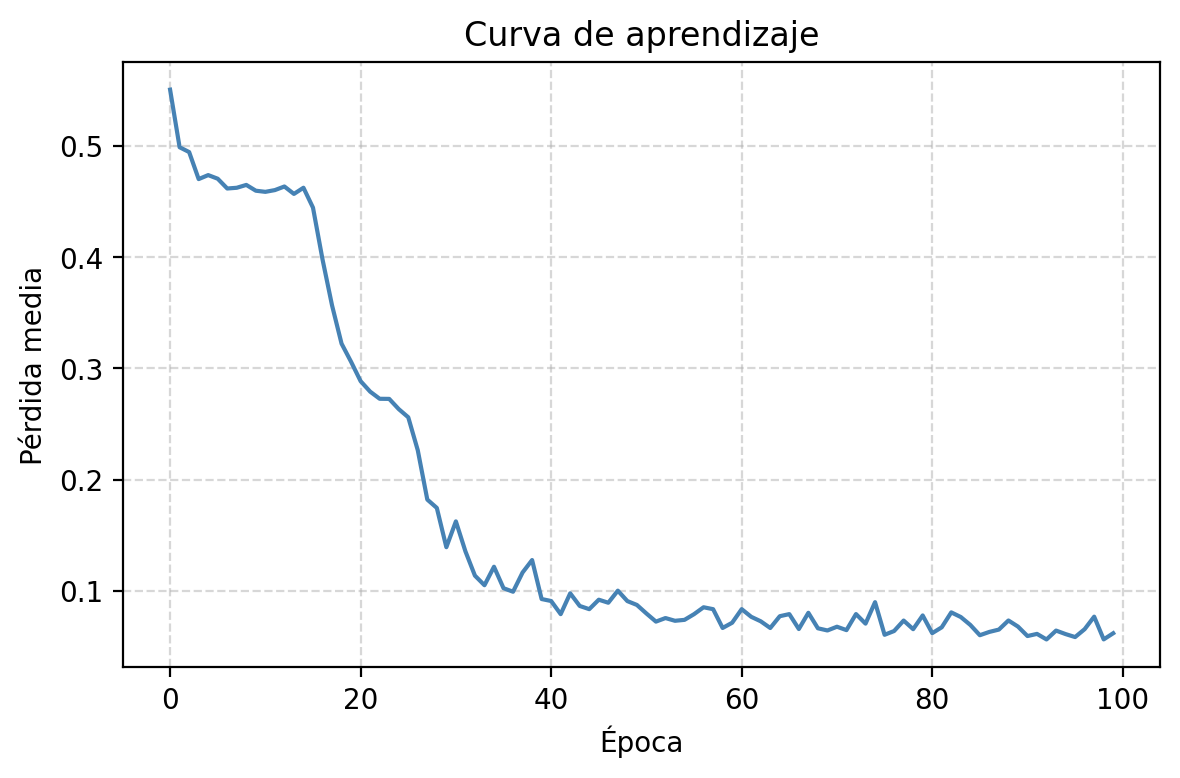

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history_cost, color="steelblue", linewidth=1.5)
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida media")
ax.set_title("Curva de aprendizaje")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Evaluación en el conjunto de test

Medimos la capacidad de generalización de la red evaluándola sobre datos que **no ha visto durante el entrenamiento**. Si la tasa de acierto en test es similar a la de entrenamiento, la red generaliza bien; si es significativamente menor, puede haber *overfitting*.

In [27]:
aciertos, predicciones = evaluar_clasificacion(X_test, y_test)
tasa_test = aciertos / NUM_PUNTOS_TEST
print("Aciertos:", int(aciertos), "de", NUM_PUNTOS_TEST)
print("tasa de acierto en test", tasa_test)

Aciertos: 1948 de 2000
tasa de acierto en test 0.974


## Visualización de los resultados en test

Dibujamos los puntos del conjunto de test coloreados según las predicciones de la red. Los puntos **rojos** indican errores de clasificación: muestras cuya clase predicha difiere de la real. Esto permite identificar visualmente en qué regiones del espacio la red tiene más dificultades.

Errores en los puntos dibujados: 34


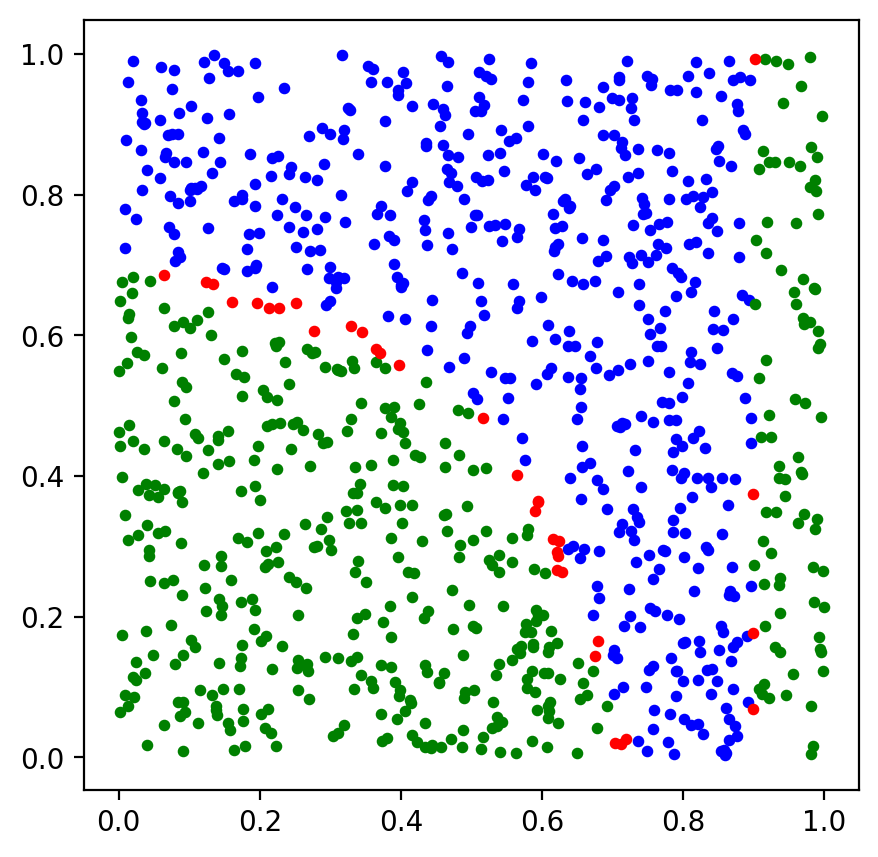

In [28]:
numpuntosplot = min(1000, NUM_PUNTOS_TEST)
datos = test_np[:numpuntosplot]
labels = predicciones[:numpuntosplot].copy()
labels[labels != datos[:, 2]] = 2          # los errores se marcan con la clase 2 (rojo)
print("Errores en los puntos dibujados:", int((labels == 2).sum()))
plot_data(datos, plabels=labels)

---

<font size="1" color="grey">
    (c) 2026 Javier García Algarra. <a href='https://www.u-tad.com'>www.u-tad.com</a> <br>
Licensed under a Creative Commons Reconocimiento 4.0 Internacional License
</font>